# **Support Vector Machine(SVM) for Classification**

In [1]:
import pandas as pd
df = pd.read_csv("1__iris.csv")
df = df.drop_duplicates()
df.shape

(147, 5)

Loads pandas, reads the file into df, and removes the 3 repeated flowers, as in earlier tasks.

In [2]:
data = df[df["species"].isin(["versicolor", "virginica"])].copy()
data["target"] = (data["species"] == "virginica").astype(int)
data["target"].value_counts()

,count
target,
0,50
1,49


df["species"].isin([...]) checks each row and gives True if its species is in the list. df[...] keeps only the True rows, so setosa is dropped. .copy() makes an independent copy, which avoids a warning later.
data["species"] == "virginica" is True for virginica rows and False for the others, and .astype(int) turns that into 1 and 0. So virginica = 1 and versicolor = 0, stored in a new column called target.

The values of target are counted


In [3]:
X = data[["petal_length", "petal_width"]]
y = data["target"]
X.describe()

,petal_length,petal_width
count,99.000000,99.000000
mean,4.904040,1.673737
std,0.829546,0.426324
min,3.000000,1.000000
25%,4.350000,1.300000
50%,4.900000,1.600000
75%,5.550000,2.000000
max,6.900000,2.500000


X keeps only the petal columns and y is the target(answer)

I decsribed X

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(79, 2) (20, 2)
target
0    40
1    39
Name: count, dtype: int64
target
1    10
0    10
Name: count, dtype: int64


imported train_test_split from scikit learn and split my X and y into train and test .
20% of the whole data frame was my test data and I made my random state to be 42 so that it is repeatable
and I stratify y so that there will be an even distrubution of all the species.


and also counts the values of the y_train and y_test dataset.

In [5]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.mean(axis=0).round(2))
print(X_train_scaled.std(axis=0).round(2))

[-0. -0.]
[1. 1.]


I standardized the numerical features. It's the most common default and it also works for many models.
I fit the scaler on the training data only, and then apply the same numbers to the test data.
The test set is meant to act like a brand new data model.If the scaler studies the test set information acquired by the machine will leak into the test set final result  and that will sabotage the whole idea of creating a test set in the first place. It is called Data Leakage.

In [6]:
from sklearn.svm import SVC
linear_svm = SVC(kernel="linear")
linear_svm.fit(X_train_scaled, y_train)
rbf_svm = SVC(kernel="rbf")
rbf_svm.fit(X_train_scaled, y_train)

SVC()

SVC stands for Support Vector Classifier which is gotten from the sklearn svm section.

SVC(kernel=...) creates a SVM that can only draw a straight boundary.  SVC(kernel="rbf") creates one that can curve
.fit... finds the for the widest between the classes, using the scaled flowers


In [7]:
print(linear_svm.score(X_train_scaled, y_train), linear_svm.score(X_test_scaled, y_test))
print(rbf_svm.score(X_train_scaled, y_train), rbf_svm.score(X_test_scaled, y_test))

0.9746835443037974 0.8
0.9620253164556962 0.85


.score calculates accuracy on first the training flower and then the test flowers.

In [8]:
print(linear_svm.n_support_, rbf_svm.n_support_)

[6 7] [7 9]


Gives the number of support vectors for each class first Versicolor and then Virginica


only 13 of the 79 training flowers (linear) and 16 (RBF) are support vectors, meaning flowers on or near the edge of the street, or on the wrong side of it. The other 60-odd flowers are far from the border, and the boundary would be exactly the same without them. The RBF kernel needs a few more because its curved boundary has to bend around more border flowers.

In [9]:
print(linear_svm.coef_, linear_svm.intercept_)

[[1.20519003 1.74063285]] [0.16090616]


For a linear SVM, the boundary is a straight line defined by one weight per column plus a starting value.

Both weights are positive, so bigger petals push a flower toward virginica, and the width weight is larger

In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix

for name, model in [("Linear", linear_svm), ("RBF", rbf_svm)]:
    y_pred = model.predict(X_test_scaled)
    scores = model.decision_function(X_test_scaled)
    print(name)
    print("accuracy", accuracy_score(y_test, y_pred))
    print("precision", precision_score(y_test, y_pred))
    print("recall", recall_score(y_test, y_pred))
    print("AUC", roc_auc_score(y_test, scores))
    print(confusion_matrix(y_test, y_pred))

Linear
accuracy 0.8
precision 0.875
recall 0.7
AUC 0.97
[[9 1]
 [3 7]]
RBF
accuracy 0.85
precision 0.8888888888888888
recall 0.8
AUC 0.97
[[9 1]
 [2 8]]


This is a loop over two pairs, so the same lines run once for each model. name holds the label and model holds the trained SVM.


odel.predict(X_test_scaled) gives each test flower’s final 0 or 1 guess.
model.decision_function(X_test_scaled) gives each flower a score: how far it sits from the boundary, with a plus or minus sign. A positive score means virginica (1) and a negative score means versicolor (0). The bigger the number, the further the flower is from the boundary, and so the more confident the model is.


inear precision 0.875. It said “virginica” 8 times (7 correct, 1 wrong).
Linear recall 0.70. There were 10 real virginica flowers, and it found 7, so it missed 3.


RBF Precision is 0.889 and recall 0.80 it said virginica 9 times and 8 was correct and it found 8 out of 10
The accuracy score is the same for the both

In [11]:
from sklearn.metrics import classification_report
print(classification_report(y_test, rbf_svm.predict(X_test_scaled), target_names=["versicolor", "virginica"]))

              precision    recall  f1-score   support

  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.85        20
   macro avg       0.85      0.85      0.85        20
weighted avg       0.85      0.85      0.85        20



Prints precision, recall, and F1 for each class, with names. Change rbf_svm to linear_svm for the other one.

In [12]:
import numpy as np
import matplotlib.pyplot as plt

x_min, x_max = X_train_scaled[:, 0].min() - 1, X_train_scaled[:, 0].max() + 1
y_min, y_max = X_train_scaled[:, 1].min() - 1, X_train_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]

numpy  is the maths library, and matplotlib draws the chart.
X_train_scaled[:, 0] is the first column (petal length) of the scaled training data, and [:, 1] is the second (petal width). .min() and .max() find the smallest and biggest values, and the - 1 and + 1 add a margin around the flowers so the picture isn't cramped.
np.linspace(x_min, x_max, 300) makes 300 evenly spaced numbers between the two ends. np.meshgrid(...) combines the two lists and stores as xx (all the across positions) and yy (all the up positions).
xx.ravel() and yy.ravel() flatten each grid into a single long list, and np.c_[...] places them side by side as columns. The result, grid_points, is 90,000 rows of (length, width), which is the format predict expects.

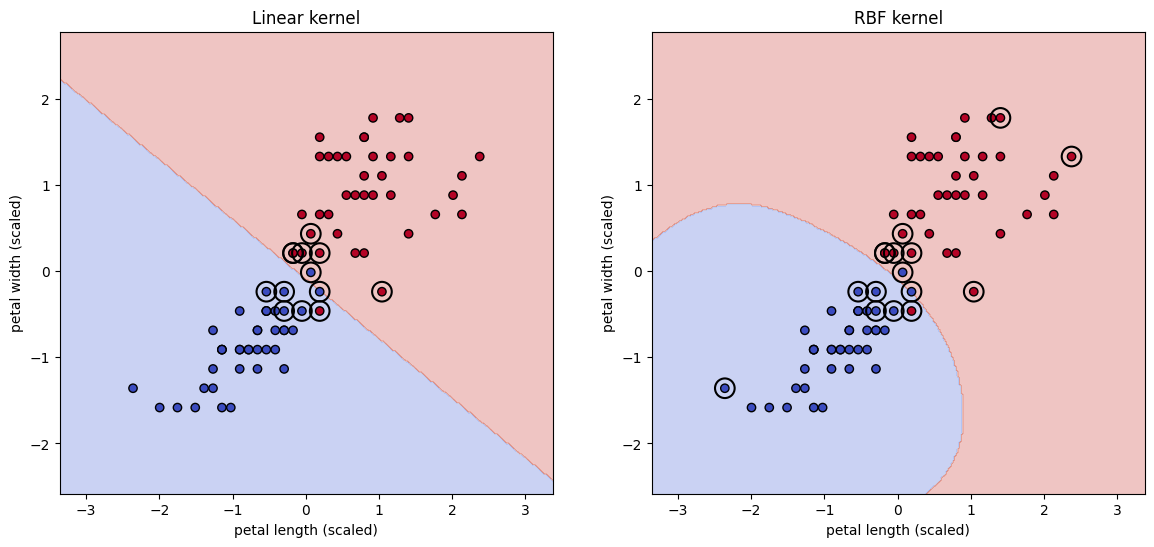

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, model, name in zip(axes, [linear_svm, rbf_svm], ["Linear kernel", "RBF kernel"]):
    zz = model.predict(grid_points).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train, cmap="coolwarm", edgecolor="k")
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=200, facecolors="none", edgecolors="black", linewidths=1.5)
    ax.set_xlabel("petal length (scaled)")
    ax.set_ylabel("petal width (scaled)")
    ax.set_title(name)
plt.show()

plt.subplots(1, 2, figsize=(14, 6)) makes one picture with two side-by-side panels, stored as axes.
zip(axes, [...], [...]) lines up each panel with its model and its title, so the loop draws the left panel for the linear model and the right panel for the RBF model

The first ax.scatter(...) draws the training flowers as dots, coloured by their real class (c=y_train), with a black edge. The second draws a large empty black circle around each support vector


The blue is versicolor and the red is virginica. small petals are at the bottom left while large petals in the top right.
Left panel (linear): a straight diagonal line separates the colours. The street runs between the two clusters.
Right panel (RBF): the boundary curves. The blue region is a rounded shape wrapped around the versicolor flowers.
In the middle of both pictures, red and blue dots mix. That's the overlap between the two species, and it's where every mistake comes from.
The circled dots are the support vectors.

In Conclusion:
The linear and RBF kernels performed almost the same, because versicolor and virginica are close to linearly separable using petal length and width. RBF got one more flower right, but with 20 test flowers that isn't enough to say it's better.